# Learning constitutive laws from a phase-separation movie

In this example, we infer the constitutive laws of a binary material, its chemical potential $\mu_h(c)$ and diffusivity $D(c)$, from a single noisy movie of spinodal decomposition. We compute a maximum a posteriori (MAP) estimate by [multiple shooting](../overview/inference/multiple-shooting.md), starting each short solve from a measured frame. A Laplace approximation around the estimate gives the uncertainty, which we check against the paper's samples from the [NUTS sampler](../overview/inference/mcmc.md). The problem follows [Zhao et al. (2021)](https://arxiv.org/abs/2010.10676) and is Worked Example 1 of the diff-soup paper.

## Setup

We import diff-soup in JAX float64 (double-precision) mode. We generate the movie in float64, and the fit runs in single precision (float32) on a GPU and in float64 on a CPU ([precision](../overview/simulation/precision.md)).

In [1]:
import time

import diff_soup as ds  # before jax, so diff-soup can configure it
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg
import scipy.optimize
from diff_soup.domains import cartesian_grid_2d
from diff_soup.inference.approx import Legendre, LegendreExpansion
from numpy.polynomial import legendre as npleg

jax.config.update("jax_enable_x64", True)
plt.rcParams.update({"figure.dpi": 100, "image.cmap": "viridis", "font.size": 9})

The next cell holds the run settings, all at the paper's values.

In [2]:
GPU = jax.default_backend() == "gpu"
PRECISION = ds.Precision.fp32() if GPU else None  # KLU, the CPU backend, factors float64 only
N = 64                     # cells per side (paper: 64)
SCALE = 1.142              # prior scale s from empirical Bayes (paper: 1.142)
FIT_TOL = 1e-4             # rtol = atol of every window solve in the fit (paper: 1e-4)
MAX_STEPS = 40             # trust-region step budget (paper: 40)
print(f"diff-soup {ds.__version__}, JAX {jax.__version__}, {jax.devices()[0].device_kind}")

diff-soup 1.1.0, JAX 0.11.2, NVIDIA GeForce RTX 4070 Ti


## The problem

We consider the composition $c(x, t)$, the local fraction of one component of a binary mixture on the unit square. It evolves according to the Cahn-Hilliard equation

$$
\frac{\partial c}{\partial t} = \nabla \cdot \big( D(c)\, c\, \nabla \mu \big), \qquad \mu = \mu_h(c) - \kappa \nabla^2 c ,
$$

where $\mu$ is the chemical potential in units of $k_B T$, $\kappa = 0.045^2$ is the gradient penalty coefficient and $D(c)$ is the tracer diffusivity of a single particle. The walls carry no flux and no wetting, $\nabla \mu \cdot n = \nabla c \cdot n = 0$.

The ground truth is a regular solution, a mixture whose components prefer their own kind, with interaction strength $\Omega = 3$,

$$
\mu_h(c) = \ln \frac{c}{1 - c} + \Omega (1 - 2c), \qquad D(c) = 1 - c .
$$

The movie starts from $c = 0.5$ plus Gaussian noise of standard deviation 0.01 in every cell. The data are six frames at geometrically spaced times from $t = 0.1$ to 1.0, with Gaussian noise of 10% of the standard deviation of the clean movie.

We parameterize both laws with Legendre polynomials $P_k$ of degree $k$, keeping the ideal entropy of mixing in $\mu_h$ and the exponential that keeps $D$ positive,

$$
\mu_h(c) = \ln \frac{c}{1 - c} + \sum_{k=1}^{12} a_k P_k(2c - 1), \qquad D(c) = \exp\Big( \sum_{k=0}^{9} b_k P_k(2c - 1) \Big).
$$

The prior on each coefficient is normal with standard deviation $s / \sqrt{1 + k(k + 1)}$, which damps the high degrees that the data cannot resolve. The MAP estimate then minimizes

$$
\frac{1}{2\sigma^2} \sum_{i=1}^{5} \big\| c(t_i; \theta, \hat c_{i-1}) - \hat c_i \big\|^2 - \ln p(\theta),
$$

where $\hat c_i$ is the frame measured at $t_i$, $\sigma$ is the noise level and $\theta = (a, b)$, with each prediction starting from the previous measured frame.

## Build the model

First, we write the true laws. Since a noisy start frame can have cells near 0 or 1, the logarithm continues linearly outside $[0.01, 0.99]$ so that it stays finite.

In [3]:
KAPPA, OMEGA = 0.045**2, 3.0


def ideal_entropy(c, knee=1e-2):
    cs = jnp.clip(c, knee, 1.0 - knee)
    return jnp.log(cs / (1.0 - cs)) + (c - cs) / (cs * (1.0 - cs))  # tangent past the knee


def mu_h_true(c):
    return ideal_entropy(c) + OMEGA * (1.0 - 2.0 * c)


def D_true(c):
    return 1.0 - c

Next, we write one recipe for both the truth and the learnable model, with $\mu_h$ and $D$ declared as functions ([the Recipe API](../overview/modeling/recipe-api.md)). The walls of the finite-volume grid are closed by default, which gives both wall conditions.

In [4]:
def cahn_hilliard(name, mu_h, D, *, learnable=False, priors=(None, None), precision=None):
    spec = ds.problem(name)
    spec.domain("square", cartesian_grid_2d(N, N, 1.0, 1.0, method="fvm"))
    spec.field("c", mass="differential", scale=1.0)
    mu_fn = spec.function("mu_h", mu_h, learnable=learnable, prior=priors[0])
    D_fn = spec.function("D", D, learnable=learnable, prior=priors[1])

    @spec.equation(writes="c", reads=("c",))
    def flux_form(q):
        mu = q.fn.mu_h(q.c) - KAPPA * q.ops.laplacian(q.c)
        return q.ops.div_flux(q.c * q.fn.D(q.c), mu)

    return spec.build(precision=precision), mu_fn, D_fn

We require the learnable $\mu_h$ to keep the miscibility gap of the truth, the range of compositions that unmix. Its edges, the binodal compositions $c_1 < c_2$, are taken as known. The conditions $\mu_h(c_1) = 0$, $\mu_h(c_2) = 0$ and $\int_{c_1}^{c_2} \mu_h \, dc = 0$ are linear in $a$, and we write them as $C a = d$.

In [5]:
MU_DEGREE, LND_DEGREE = 12, 9


def miscibility_gap(degree):
    f = lambda c: np.log(c / (1 - c)) + OMEGA * (1 - 2 * c)
    c1 = scipy.optimize.brentq(f, 1e-9, 0.5 - 1e-9)
    x = np.array([2 * c1 - 1, 1 - 2 * c1])  # c1 and c2 = 1 - c1, mapped onto [-1, 1]
    eye = np.eye(degree + 1)
    area = [0.5 * np.diff(npleg.legval(x, npleg.legint(eye[k])))[0] for k in range(degree + 1)]
    C = np.vstack([npleg.legvander(x, degree), area])[:, 1:]  # a_0 is not a coefficient
    cs = np.linspace(c1, 1 - c1, 20001)
    logit = np.log(cs / (1 - cs))
    d = -np.array([logit[0], logit[-1], np.trapezoid(logit, cs)])
    return C, d, (c1, 1 - c1)

Every solution is then $a = a_p + A \xi$, where $a_p$ is the solution of least weighted norm and the columns of $A$ span the null space of $C$. We make the columns orthonormal under the prior weights $1 + k(k + 1)$, so that an isotropic prior on $\xi$ is the degree-weighted prior on $a$, restricted to the conditions.

In [6]:
C, d, (C1, C2) = miscibility_gap(MU_DEGREE)
k = np.arange(1, MU_DEGREE + 1)
w = 1.0 + k * (k + 1.0)  # prior precision weights of a_1 .. a_12
A = scipy.linalg.null_space(C)
ev, V = np.linalg.eigh(A.T @ (w[:, None] * A))
A = A @ V @ np.diag(ev**-0.5) @ V.T  # now A^T diag(w) A = I
A *= np.sign(A[np.abs(A).argmax(axis=0), np.arange(A.shape[1])])  # fix the signs
a_p = (C.T / w[:, None]) @ np.linalg.solve((C / w) @ C.T, d)
print(f"binodal ({C1:.4f}, {C2:.4f}), {A.shape[1]} free coordinates")

binodal (0.0707, 0.9293), 9 free coordinates


We wrap $\mu_h$ in an Equinox module whose only array field is $\xi$, so the fit and the prior see nine coefficients for $\mu_h$ ([function approximation](../overview/inference/function-approximation.md)). For the diffusivity, we use the built-in `Legendre` expansion of $\ln D$ with an exponential transform.

In [7]:
class ChemicalPotential(eqx.Module):
    xi: jax.Array
    a_p: tuple = eqx.field(static=True)
    A: tuple = eqx.field(static=True)

    def __call__(self, c):
        a = jnp.asarray(self.a_p, self.xi.dtype) + jnp.asarray(self.A, self.xi.dtype) @ self.xi
        excess = LegendreExpansion(jnp.concatenate([jnp.zeros(1, a.dtype), a]))
        return ideal_entropy(c) + excess(2.0 * jnp.clip(c, 0.0, 1.0) - 1.0)


def mu_h_law(xi):
    return ChemicalPotential(jnp.asarray(xi), tuple(a_p.tolist()), tuple(map(tuple, A.tolist())))


def exp_transform(c, p):
    return jnp.exp(p)


def D_law(b):
    return Legendre(jnp.asarray(b), interval=(0.0, 1.0), transform=exp_transform, clip=(0.0, 1.0))

## Synthetic data

We generate the movie by solving the truth from the noisy start at $\mathrm{rtol} = 10^{-8}$ and $\mathrm{atol} = 10^{-10}$, saving the six frames.

In [8]:
TIMES = np.array([0.1, 0.16, 0.25, 0.4, 0.63, 1.0])
truth, _, _ = cahn_hilliard("truth", mu_h_true, D_true)
c_start = 0.5 + 0.01 * np.random.default_rng(1001).standard_normal(N * N)
t0 = time.perf_counter()
sol = ds.pdesolve(truth, ds.JIDA(rtol=1e-8, atol=1e-10), (0.0, 1.0), jnp.asarray(c_start),
                  saveat=ds.SaveAt(ts=jnp.asarray(TIMES)))
clean = np.asarray(sol.ys)
print(f"reached t = 1: {bool(sol.ok)}, {int(sol.stats.accepts)} steps, "
      f"{time.perf_counter() - t0:.1f} s with compilation")

reached t = 1: True, 2095 steps, 2.7 s with compilation


The noise level $\sigma$ is 10% of the standard deviation of the clean movie, and clipping to $[0.01, 0.99]$ keeps every measured value inside $(0, 1)$.

sigma = 0.0336, noise floor sigma^2 = 1.13e-03


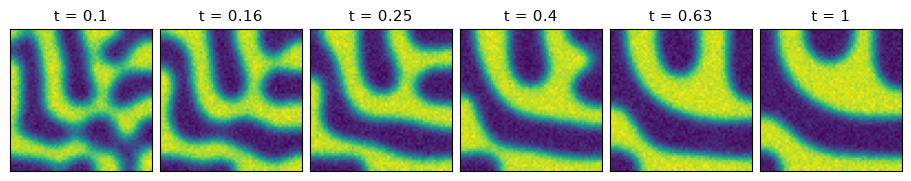

In [9]:
sigma = 0.10 * clean.std()
rng = np.random.default_rng(2001)
noisy = np.clip(clean + sigma * rng.standard_normal(clean.shape), 0.01, 0.99)
print(f"sigma = {sigma:.4f}, noise floor sigma^2 = {sigma**2:.2e}")

fig, axes = plt.subplots(1, 6, figsize=(9, 1.8), layout="constrained")
for ax, frame, t in zip(axes, noisy, TIMES):
    ax.imshow(frame.reshape(N, N).T, origin="lower", vmin=0, vmax=1)
    ax.set(title=f"t = {t:g}", xticks=[], yticks=[])
plt.show()

The pattern has formed by the first frame and coarsens over the rest, with most cells near the two binodal compositions.

## MAP fit

The learnable model starts from $\xi = 0$ and a constant $D = 0.5$, and both priors are centred on these starting coefficients with scale $s$.

In [10]:
mu_start = mu_h_law(np.zeros(A.shape[1]))
D_start = D_law(np.r_[np.log(0.5), np.zeros(LND_DEGREE)])


def learnable_model(scale, precision):
    priors = (ds.inference.GaussianCoefficientPrior(scale=scale, smoothness=0.0),  # isotropic in xi
              ds.inference.GaussianCoefficientPrior(scale=scale, smoothness=1.0))  # weights 1 + k(k + 1)
    return cahn_hilliard("learnable", mu_start, D_start, learnable=True, priors=priors,
                         precision=precision)

`Windows.from_data` starts every window from a measured frame, so that five short solves replace one long one ([multiple shooting](../overview/inference/multiple-shooting.md)). Only the laws are fitted, so there is no continuity term between the windows. We build the inference problem in a function of the solver tolerance, since the sampler at the end needs a tighter one.

In [11]:
movie = ds.inference.Measurement("c", times=jnp.asarray(TIMES), values=jnp.asarray(noisy),
                                 likelihood=ds.inference.Gaussian(sigma=float(sigma)))


def inference_problem(tol, scale=SCALE, precision=PRECISION):
    model, mu_fn, D_fn = learnable_model(scale, precision)
    experiment = ds.inference.Experiment(
        model=model, solver=ds.JIDA(rtol=tol, atol=tol), t_span=(float(TIMES[0]), float(TIMES[-1])),
        initial_state=jnp.asarray(noisy[0]), measurements=(movie,),
        trajectory=ds.inference.Multishoot(ds.inference.Windows.from_data(source="c")))
    est = ds.inference.InferenceProblem(experiment, parameters=(mu_fn, D_fn), objective=ds.inference.MAP())
    return est, mu_fn, D_fn


est, mu_fn, D_fn = inference_problem(FIT_TOL)
print(f"{est.n_params} coefficients, {est.n_segments} windows")

19 coefficients, 5 windows


To draw the movies and the error curve in the results, a callback records the coefficients and the cost after every step. Its `info.params` is one flat vector in the fit's order, and `est.values(x)[mu_fn]` reads one law from such a vector.

In [12]:
class History(ds.inference.Callback):
    def __init__(self):
        self.params, self.cost, self.accepted = [], [], []

    def on_step(self, info):
        self.params.append(np.asarray(info.params))
        self.cost.append(float(info.cost))
        self.accepted.append(bool(info.accepted))

We fit with the Newton trust-region method, which steps on the Gauss-Newton approximation of the Hessian ([optimization solvers](../overview/inference/solvers.md)). The printed time includes the jit compile of the window solves.

In [13]:
history = History()
optimizer = ds.inference.NewtonTrustRegion(max_steps=MAX_STEPS)
t0 = time.perf_counter()
fit = ds.inference.optsolve(est, optimizer, callbacks=(history,), diagnostics=False)
t_fit = time.perf_counter() - t0
n_rows = est.n_segments * N * N  # one residual per cell of each predicted frame
mse = 2.0 * sigma**2 * np.asarray(fit.cost_history) / n_rows
print(f"{fit.status}, {fit.n_steps} steps ({sum(history.accepted)} accepted), {t_fit:.0f} s")
print(f"MSE {mse[0]:.2e} -> {mse[-1]:.2e}, noise floor {sigma**2:.2e}")

TerminationStatus.STEP_TOL, 25 steps (14 accepted), 21 s
MSE 2.21e-02 -> 1.14e-03, noise floor 1.13e-03


In 25 steps the mean squared error falls from $2.21 \times 10^{-2}$ to $1.14 \times 10^{-3}$, at the noise floor of $1.13 \times 10^{-3}$. We confirm this with the standardized residuals and then evaluate the learned laws, `fit[mu_fn]` and `fit[D_fn]`, against the truth.

In [14]:
res = ds.inference.residual_report(est, fit).channels["c"]
print(f"standardized residuals: std {res.std:.3f}, mean {res.mean:+.3f}")
c_grid = np.linspace(C1, C2, 201)
mu_fit, D_fit = (np.asarray(fit[fn](jnp.asarray(c_grid))) for fn in (mu_fn, D_fn))
mu_ref, D_ref = np.asarray(mu_h_true(c_grid)), D_true(c_grid)


def rel_l2(f, g):
    return np.sqrt(np.trapezoid((f - g) ** 2, c_grid) / np.trapezoid(g**2, c_grid))


print(f"relative L2 error on the binodal range: mu_h {rel_l2(mu_fit, mu_ref):.3f}, "
      f"D {rel_l2(D_fit, D_ref):.3f}")

standardized residuals: std 0.918, mean +0.018


relative L2 error on the binodal range: mu_h 0.053, D 0.050


The standardized residuals have a mean near zero and a standard deviation of 0.918, close to the value of one that the noise model expects. Both learned laws are within about 5% of the truth in relative $L^2$ error over the binodal range.

## Choosing the prior scale

The scale $s$ sets how far the prior lets the coefficients move. The paper picks it by empirical Bayes, maximizing the Laplace approximation to the evidence $p(\hat c \mid s)$ over six refits, and the resulting $s = 1.142$ is set in the config cell.

`ds.inference.evidence` returns the Laplace log evidence of a MAP fit ([standard errors and covariance](../overview/inference/statistical-estimation.md#standard-errors-and-covariance)). It refuses a fit that has not reached a stationary point to within what its solver tolerance allows, and this fit passes as it is.

In [15]:
ev = ds.inference.evidence(est, fit, curvature="expected")
print(f"ln p(c | s = {SCALE}) = {ev.log_evidence:.1f}")

ln p(c | s = 1.142) = 50441.4


A scan over $s$ needs no refit. We keep the Gauss-Newton curvature $H$ of the data term from this fit and treat the log likelihood $\ell$ as quadratic around $\hat\theta$. With the prior precision $P_s$, the offset $e = \hat\theta - \theta_0$ from the prior centre and the gradient $g = \nabla \ell(\hat\theta)$, the evidence is a Gaussian integral with the closed form

$$
\ln p(\hat c \mid s) \approx \ell(\hat\theta) - \tfrac{1}{2} e^\top P_s e + \tfrac{1}{2} b^\top (H + P_s)^{-1} b + \tfrac{1}{2} \ln \frac{\det P_s}{\det (H + P_s)}, \qquad b = g - P_s e.
$$

In [16]:
info = ds.inference.information(est, at=fit, kind="expected")
H = np.asarray(info.expected, float)  # Gauss-Newton curvature of the data term
P1 = np.asarray(info.prior_precision, float) * SCALE**2  # prior precision at s = 1
theta0 = np.r_[np.zeros(A.shape[1]), np.log(0.5), np.zeros(LND_DEGREE)]
e = np.asarray(fit.params, float) - theta0
g = P1 @ e / SCALE**2  # at the MAP the data gradient balances the prior gradient


def log_evidence(s):
    P = P1 / s**2
    b = g - P @ e
    return (ev.log_likelihood_at_mode - 0.5 * e @ P @ e + 0.5 * b @ np.linalg.solve(H + P, b)
            + 0.5 * (np.linalg.slogdet(P)[1] - np.linalg.slogdet(H + P)[1]))


print(f"at s = {SCALE}: scan {log_evidence(SCALE):.2f}, ds.inference.evidence {ev.log_evidence:.2f}")

at s = 1.142: scan 50441.35, ds.inference.evidence 50441.35


cheap-scan optimum s = 0.95, ln p(s = 1.142) - ln p(s = 0.95) = -0.53


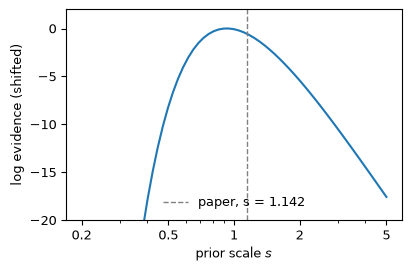

In [17]:
scales = np.geomspace(0.2, 5.0, 61)
scan = np.array([log_evidence(s) for s in scales])
best = scales[np.argmax(scan)]
print(f"cheap-scan optimum s = {best:.2f}, "
      f"ln p(s = {SCALE}) - ln p(s = {best:.2f}) = {log_evidence(SCALE) - scan.max():.2f}")

fig, ax = plt.subplots(figsize=(4, 2.6), layout="constrained")
ax.semilogx(scales, scan - scan.max())
ax.axvline(SCALE, color="0.5", ls="--", lw=1, label=f"paper, s = {SCALE}")
ax.set(xlabel="prior scale $s$", ylabel="log evidence (shifted)", ylim=(-20, 2))
ax.set_xticks([0.2, 0.5, 1, 2, 5], ["0.2", "0.5", "1", "2", "5"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.legend(frameon=False)
plt.show()

At $s = 1.142$ the scan reproduces `ds.inference.evidence`, and the curve is flat near its top. The paper's value and the scan's optimum of 0.95 differ by 0.53 in log evidence, less than one unit, so either gives nearly the same fit.

## Posterior

The Laplace approximation is a Gaussian centred on the fit, with the inverse curvature as its covariance ([standard errors and covariance](../overview/inference/statistical-estimation.md#standard-errors-and-covariance)). It costs one curvature evaluation, and its draws cost no solves.

In [18]:
laplace = ds.inference.laplace(est, fit, curvature="expected")
sd_laplace = np.asarray(laplace.marginal_sd())
print("Laplace sd, mu_h xi:", np.round(sd_laplace[:9], 3))
print("Laplace sd, ln D b: ", np.round(sd_laplace[9:], 3))

Laplace sd, mu_h xi: [0.192 0.517 0.213 0.645 0.213 0.519 0.181 0.448 0.358]
Laplace sd, ln D b:  [0.019 0.058 0.092 0.121 0.124 0.136 0.131 0.123 0.11  0.097]


Each draw is a coefficient vector, so the credible band of a law is the pointwise spread of that law over the draws.

In [19]:
def bands(rows):  # rows of flat parameter vectors -> 95% bands of mu_h and D on the c grid
    c = jnp.asarray(c_grid)
    mu = jax.vmap(lambda x: est.values(x)[mu_fn](c))(jnp.asarray(rows))
    D = jax.vmap(lambda x: est.values(x)[D_fn](c))(jnp.asarray(rows))
    return np.percentile(np.asarray(mu), [2.5, 97.5], axis=0), np.percentile(np.asarray(D), [2.5, 97.5], axis=0)


def coverage(band, ref):  # the fraction of the c grid where the truth lies inside the band
    return np.mean((ref >= band[0]) & (ref <= band[1]))


rows = np.asarray(laplace.sample(jax.random.PRNGKey(0), 2000))
mu_band, D_band = bands(rows)
print(f"truth inside the Laplace band: mu_h {coverage(mu_band, mu_ref):.0%}, D {coverage(D_band, D_ref):.0%}")

truth inside the Laplace band: mu_h 81%, D 98%


## Results

Each predicted movie is one solve from the first measured frame with the laws after a given number of accepted steps. Since the fit never runs this long solve, it tests the laws over the whole movie.

In [20]:
iterates = [np.asarray(fit.initial_params)] + [p for p, a in zip(history.params, history.accepted) if a]


def predict_movie(params):
    values = est.values(params)
    m, _, _ = cahn_hilliard("predict", values[mu_fn], values[D_fn], precision=PRECISION)
    s = ds.pdesolve(m, ds.JIDA(rtol=FIT_TOL, atol=FIT_TOL), (float(TIMES[0]), float(TIMES[-1])),
                    jnp.asarray(noisy[0]), saveat=ds.SaveAt(ts=jnp.asarray(TIMES)))
    return np.asarray(s.ys)


shown = {"measured": noisy, "iterate 0": predict_movie(iterates[0]),
         "iterate 7": predict_movie(iterates[7]), "learned": predict_movie(iterates[-1])}

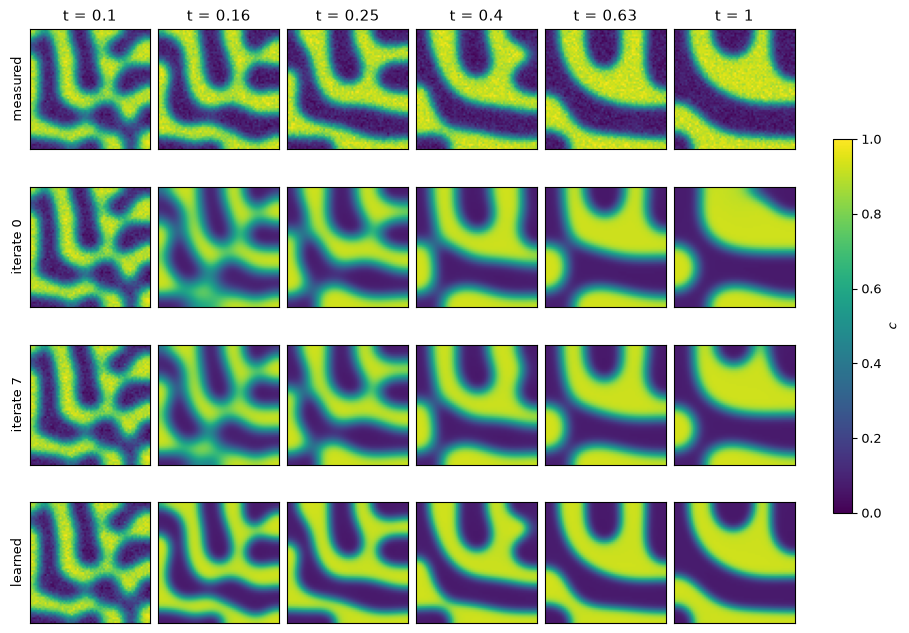

In [21]:
fig, axes = plt.subplots(4, 6, figsize=(9, 6.4), layout="constrained")
for row, (label, frames) in zip(axes, shown.items()):
    for ax, frame in zip(row, frames):
        image = ax.imshow(np.asarray(frame).reshape(N, N).T, origin="lower", vmin=0, vmax=1)
        ax.set(xticks=[], yticks=[])
    row[0].set_ylabel(label)
for ax, t in zip(axes[0], TIMES):
    ax.set_title(f"t = {t:g}")
fig.colorbar(image, ax=axes, shrink=0.6, label="$c$")
plt.show()

The starting laws coarsen the pattern too fast. Iterate 7, where the error starts to drop quickly, is closer, and the learned laws follow the measured movie to the last frame.

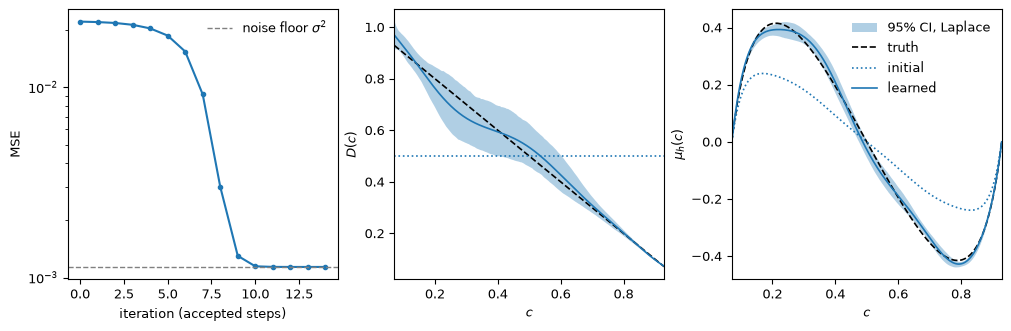

In [22]:
accepted_cost = [fit.cost_history[0]] + [c for c, a in zip(history.cost, history.accepted) if a]
mse_it = 2.0 * sigma**2 * np.asarray(accepted_cost) / n_rows
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), layout="constrained")
axes[0].semilogy(mse_it, "o-", ms=3)
axes[0].axhline(sigma**2, color="0.5", ls="--", lw=1, label="noise floor $\\sigma^2$")
axes[0].set(xlabel="iteration (accepted steps)", ylabel="MSE")
axes[0].legend(frameon=False)
laws = ((D_band, D_ref, D_fit, D_start, "$D(c)$"), (mu_band, mu_ref, mu_fit, mu_start, "$\\mu_h(c)$"))
for ax, (band, ref, learned, start, label) in zip(axes[1:], laws):
    ax.fill_between(c_grid, *band, color="C0", alpha=0.35, lw=0, label="95% CI, Laplace")
    ax.plot(c_grid, ref, "k--", lw=1.2, label="truth")
    ax.plot(c_grid, np.asarray(start(jnp.asarray(c_grid))), "C0:", lw=1.2, label="initial")
    ax.plot(c_grid, learned, "C0-", lw=1.2, label="learned")
    ax.set(xlabel="$c$", ylabel=label, xlim=(C1, C2))
axes[2].legend(frameon=False)
plt.show()

The learned laws lie close to the truth near the two binodal compositions, where most measured cells sit. Inside the spinodal region ($0.21 < c < 0.79$), where a mixture is unstable and unmixes at once, few cells are measured. The laws there rest more on the prior, and their bands widen.

## Comparison with the paper

The paper's numbers in the next cell come from its saved results, and its bands are the NUTS ones.

In [23]:
paper = {"MAP steps": 25, "rel. L2 error, mu_h": 0.053, "rel. L2 error, D": 0.047,
         "truth in band, mu_h": "81%", "truth in band, D": "98%"}
here = {"MAP steps": fit.n_steps, "rel. L2 error, mu_h": round(rel_l2(mu_fit, mu_ref), 3),
        "rel. L2 error, D": round(rel_l2(D_fit, D_ref), 3),
        "truth in band, mu_h": f"{coverage(mu_band, mu_ref):.0%}", "truth in band, D": f"{coverage(D_band, D_ref):.0%}"}
for key, value in paper.items():
    print(f"{key:20s} paper {str(value):>6s}   here {str(here[key]):>6s}")

MAP steps            paper     25   here     25
rel. L2 error, mu_h  paper  0.053   here  0.053
rel. L2 error, D     paper  0.047   here   0.05
truth in band, mu_h  paper    81%   here    81%
truth in band, D     paper    98%   here    98%


A sharper check than the band coverage is to compare the marginal standard deviations with the paper's, from its 1600 NUTS draws.

In [24]:
paper_sd = np.array([0.192, 0.501, 0.208, 0.629, 0.227, 0.503, 0.186, 0.448, 0.372, 0.018,
                     0.060, 0.088, 0.125, 0.125, 0.138, 0.127, 0.125, 0.111, 0.097])  # xi, then b
r = sd_laplace / paper_sd
print(f"Laplace sd here / paper NUTS sd: min {r.min():.2f}, median {np.median(r):.2f}, max {r.max():.2f}")

Laplace sd here / paper NUTS sd: min 0.94, median 1.00, max 1.06


The Laplace widths agree with the paper's NUTS widths to within 6%. The posterior is therefore close to Gaussian, and the Laplace bands can stand in for the NUTS ones here.

## Sampling with NUTS

NUTS, the No-U-Turn Sampler, samples the full posterior with no Gaussian assumption ([posterior sampling](../overview/inference/mcmc.md)), at a far higher cost than the Laplace approximation. In our runs on an L40S, the NUTS widths were $0.83\times$ to $1.12\times$ the Laplace ones.

The next cell holds the NUTS setup, commented out since it runs far longer than the rest of the notebook. It samples the problem rebuilt at $\mathrm{rtol} = \mathrm{atol} = 10^{-6}$, as in the paper, since NUTS needs a smoother log density than the fit. The chains start from the fit at the looser tolerance.

In [25]:
# est_sampler, _, _ = inference_problem(1e-6)  # the sampler's tolerance (paper: 1e-6)
# draws = ds.inference.sample(
#     est_sampler, fit, kernel="nuts", chains=4, warmup=100, draws=50,  # paper: 4 runs of 4 chains, 200 + 100
#     adapt="pooled", curvature="expected", key=jax.random.PRNGKey(0))  # chains whitened by the Laplace fit
# report = ds.inference.mcmc_report(draws)
# print(report.summary())
# mu_band, D_band = bands(draws.values.reshape(-1, est.n_params))

The setup runs four chains of 100 warmup steps and 50 draws, half the paper's, whitened by the Laplace fit. On an L40S, it took about 22 min and ended with a maximum R-hat of 0.995, a bulk effective sample size of 200 and no divergent transitions. Each draw took about 7 leapfrog steps. On the RTX 4070 Ti it did not finish within half an hour.

Those runs adapted the step size on one chain and shared it with the others, and a run with 60 warmup steps ended with a maximum R-hat of 1.06. The setup now uses pooled adaptation, the default for several chains, which adapts from all four chains at every warmup step, and we have not rerun it.

The paper ran four runs of four chains on an A100, each with 200 warmup steps and 100 kept draws. To reproduce it, set `warmup=200, draws=100` and pool the draws of four keys.

!!! tip
    `draws.info["adaptation"]` records the adapted step size and the acceptance rate. Check it, together with the `mcmc_report`, before you trust a short warmup.